In [1]:
import pandas as pd
import numpy as np
import sys
from pathlib import Path
from sklearn.linear_model import RidgeCV

DIR_ROOT = Path.cwd().parent.parent.parent
sys.path.insert(0, str(DIR_ROOT))

%load_ext autoreload
%autoreload 2

In [2]:
TRACK = "off_market"                     # "off_market" or "list_aware", reads oof_preds/<TRACK>/
BASE_MODELS = None                        # list of MODEL_NAMEs to stack, or None for every file in oof_preds/<TRACK>/
ALPHAS = np.logspace(-4, 3, 50)           # ridge penalties to search over

META_MODELS = {
    "ridge": lambda: RidgeCV(alphas=ALPHAS),
}

In [3]:
from training_utils import OOF_DIR, VALIDATION_MONTHS

paths = sorted((OOF_DIR / TRACK).glob("*.parquet"))
if BASE_MODELS is not None:
    paths = [path for path in paths if path.stem in BASE_MODELS]
if not paths:
    raise FileNotFoundError(f"No out-of-fold predictions in {OOF_DIR / TRACK}. Run the training notebooks first.")

oof = {path.stem: pd.read_parquet(path).set_index("ml_num") for path in paths}
for name, preds in oof.items():
    print(f"{name:<20} {len(preds):>7,} homes  {preds['month'].min()} to {preds['month'].max()}")

# One column of log price predictions per base model, keeping only homes every model predicted.
X = pd.concat({name: np.log(preds["predicted_price"]) for name, preds in oof.items()}, axis=1, join="inner")
homes = next(iter(oof.values())).loc[X.index, ["month", "house_type_name", "sold_price"]].sort_values("month")
X = X.loc[homes.index]
y = np.log(homes["sold_price"])

val_months = [str(month) for month in VALIDATION_MONTHS]
is_val = homes["month"].isin(val_months)
print(f"\nbase models: {list(X.columns)}")
print(f"meta train: {(~is_val).sum():,} homes from {homes.loc[~is_val, 'month'].min()} to {homes.loc[~is_val, 'month'].max()}")
print(f"meta val:   {is_val.sum():,} homes from {val_months[0]} to {val_months[-1]}")

catboost              22,238 homes  2025-06 to 2026-05
lightgbm              22,238 homes  2025-06 to 2026-05
lightgbm_split_apartment  22,238 homes  2025-06 to 2026-05
xgboost               22,238 homes  2025-06 to 2026-05

base models: ['catboost', 'lightgbm', 'lightgbm_split_apartment', 'xgboost']
meta train: 12,169 homes from 2025-06 to 2025-11
meta val:   10,069 homes from 2025-12 to 2026-05


In [4]:
def mdape_log(y_log, pred_log):
    return 100 * np.median(np.abs(np.exp(pred_log) / np.exp(y_log) - 1))

def mape_log(y_log, pred_log):
    return 100 * np.mean(np.abs(np.exp(pred_log) / np.exp(y_log) - 1))


def meta_walk_forward(make_meta, months=val_months, debug=True):
    """Each validation month is predicted by a meta model fit on the base predictions of
    every earlier month, the way the base models are validated.
    Returns the last month's meta model and the log price predictions of every month."""
    predictions = []
    for month in months:
        is_train, is_month = homes["month"] < month, homes["month"] == month
        meta = make_meta().fit(X[is_train], y[is_train])
        pred = pd.Series(meta.predict(X[is_month]), index=X.index[is_month])
        predictions.append(pred)
        if debug:
            print(f"{month}: trained on {is_train.sum():,} homes, predicted {is_month.sum():,}  "
                  f"MdAPE {mdape_log(y[is_month], pred):.2f}%  MAPE {mape_log(y[is_month], pred):.2f}%", flush=True)
    predictions = pd.concat(predictions)
    if debug:
        y_pred = y.loc[predictions.index]
        print(f"total: predicted {len(predictions):,} homes  "
              f"MdAPE {mdape_log(y_pred, predictions):.2f}%  MAPE {mape_log(y_pred, predictions):.2f}%", flush=True)
    return meta, predictions

In [5]:
meta_models, meta_preds = {}, {}
for name, make_meta in META_MODELS.items():
    print(name)
    meta_models[name], meta_preds[name] = meta_walk_forward(make_meta)
    print()

ridge
2025-12: trained on 12,169 homes, predicted 1,238  MdAPE 7.27%  MAPE 9.53%
2026-01: trained on 13,407 homes, predicted 1,058  MdAPE 7.61%  MAPE 10.17%
2026-02: trained on 14,465 homes, predicted 1,442  MdAPE 7.53%  MAPE 9.93%
2026-03: trained on 15,907 homes, predicted 1,816  MdAPE 7.24%  MAPE 9.57%
2026-04: trained on 17,723 homes, predicted 2,224  MdAPE 7.22%  MAPE 9.70%
2026-05: trained on 19,947 homes, predicted 2,291  MdAPE 7.34%  MAPE 9.96%
total: predicted 10,069 homes  MdAPE 7.33%  MAPE 9.80%



In [6]:
# Every candidate scored on the same validation homes.
X_val, y_val = X[is_val], y[is_val]
candidates = {name: X_val[name] for name in X_val.columns}
candidates["simple average"] = X_val.mean(axis=1)
candidates["median"] = X_val.median(axis=1)
for name, pred in meta_preds.items():
    candidates[f"meta ({name})"] = pred.loc[X_val.index]

scores = pd.DataFrame({
    "MdAPE": {name: mdape_log(y_val, pred) for name, pred in candidates.items()},
    "MAPE": {name: mape_log(y_val, pred) for name, pred in candidates.items()},
}).round(2).sort_values("MdAPE")
scores

,MdAPE,MAPE
meta (ridge),7.33,9.80
median,7.52,10.02
xgboost,7.55,10.22
simple average,7.56,10.04
lightgbm,7.66,10.22
lightgbm_split_apartment,7.69,10.18
catboost,8.46,10.99


In [7]:
# Weights of each meta model trained for the last validation month.
weights = pd.DataFrame({name: pd.Series(meta.coef_, index=X.columns) for name, meta in meta_models.items()})
weights.loc["intercept"] = [meta.intercept_ for meta in meta_models.values()]
weights.loc["sum of weights"] = weights.drop(index="intercept").sum()
if "ridge" in meta_models:
    print(f"ridge alpha: {meta_models['ridge'].alpha_:.4g}")
weights.round(4)

ridge alpha: 1


,ridge
catboost,-0.0192
lightgbm,0.2464
lightgbm_split_apartment,0.4138
xgboost,0.3744
intercept,-0.2228
sum of weights,1.0153


Diagnostics for meta (ridge)


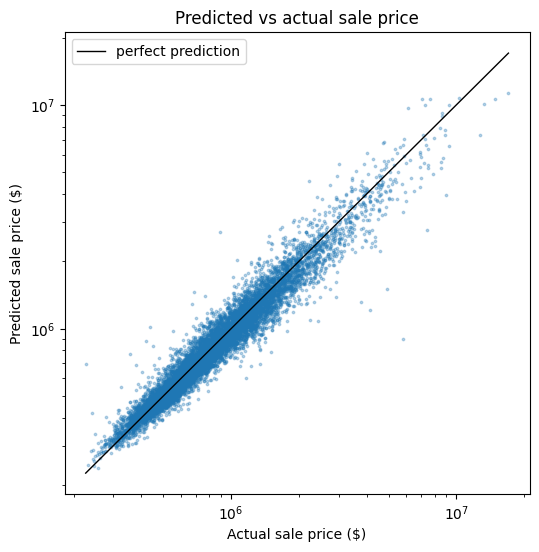

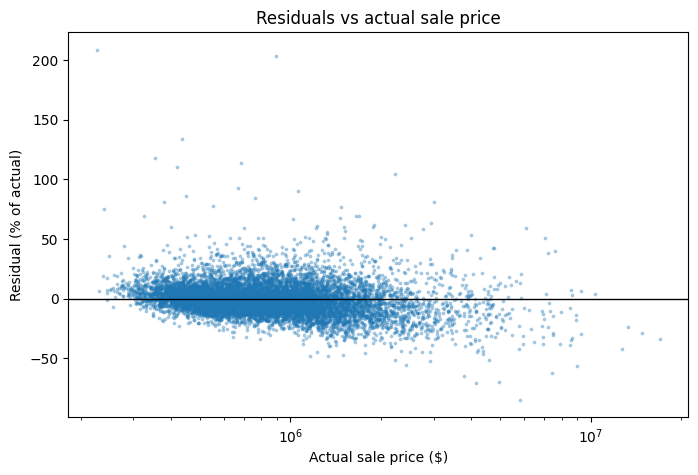

,month,house_type_name,sold_price,actual_price,predicted_price,error_pct
ml_num,,,,,,
SYN-0138680,2026-03,Condo Apt,226200.0,226200.0,698218.0,208.7
SYN-0031235,2026-05,Detached,892200.0,892200.0,2703447.0,203.0
SYN-0087681,2026-05,Co-Op Apt,434400.0,434400.0,1013984.0,133.4
SYN-0042294,2025-12,Condo Apt,354700.0,354700.0,772703.0,117.8
SYN-0150751,2026-01,Condo Apt,686300.0,686300.0,1463767.0,113.3
SYN-0083582,2026-03,Condo Apt,418100.0,418100.0,877891.0,110.0
SYN-0012460,2026-04,Semi-Detached,2227900.0,2227900.0,4549891.0,104.2
SYN-0005173,2026-01,Condo Apt,669100.0,669100.0,1291471.0,93.0
SYN-0065135,2026-03,Detached,1061500.0,1061500.0,2020648.0,90.4


In [8]:
import diagnostics

best = scores.index[0]
print(f"Diagnostics for {best}")
actual = homes.loc[X_val.index, "sold_price"]
predicted = np.round(np.exp(candidates[best]))

diagnostics.plot_predicted_vs_actual(actual, predicted)
diagnostics.plot_residuals_vs_actual(actual, predicted)
diagnostics.worst_predictions(homes.loc[X_val.index], actual, predicted)